# **ViTmodel**

**Mount Drive & Install Packages**

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Install required packages
!pip install split-folders transformers

In [ ]:
# Dataset splitting
import os
import splitfolders

# Define paths
unsplit_path = "/content/drive/MyDrive/artstyleproject/processeddataset_classification2"
output_path = "/content/processeddataset_classification22"

# Verify and split dataset
if not os.path.exists(unsplit_path):
    print(f"Error: Path not found - {unsplit_path}")
    print("Available folders in /content/drive/MyDrive:")
    !ls "/content/drive/MyDrive"
else:
    print("Dataset found successfully!")
    splitfolders.ratio(
        input=unsplit_path,
        output=output_path,
        seed=42,
        ratio=(0.6, 0.2, 0.2),
        group_prefix=None,
        move=False
    )

Dataset found successfully!


Copying files: 52100 files [38:30, 22.55 files/s]



**imports**

In [ ]:
# Import remaining libraries
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                            f1_score, confusion_matrix, roc_curve, auc,
                            classification_report)
from sklearn.preprocessing import label_binarize

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, random_split
from torchvision import transforms, models
from torchvision.datasets import ImageFolder
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau

from transformers import ViTForImageClassification, ViTConfig
from PIL import Image

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

In [ ]:
# Define paths after splitting
data_dir = "/content/processeddataset_classification22"
train_dir = os.path.join(data_dir, "train")
val_dir = os.path.join(data_dir, "val")
test_dir = os.path.join(data_dir, "test")

# Verify structure
print("Class names:", os.listdir(train_dir))
print("Train samples:", len(os.listdir(os.path.join(train_dir, os.listdir(train_dir)[0]))))
print("Val samples:", len(os.listdir(os.path.join(val_dir, os.listdir(val_dir)[0]))))
print("Test samples:", len(os.listdir(os.path.join(test_dir, os.listdir(test_dir)[0]))))

# Define your classes
classes = ["Impressionism", "Baroque", "Realism", "Romanticism", "Expressionism"]
num_classes = len(classes)

Class names: ['romanticism', 'expressionism', 'impressionism', 'realism', 'baroque']
Train samples: 6253
Val samples: 2084
Test samples: 2085


In [ ]:
# Define image transformations
image_size = 224

train_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transform = val_transform

**Dataset Splitting**

In [ ]:
# Create datasets
train_dataset = ImageFolder(root=train_dir, transform=train_transform)
val_dataset = ImageFolder(root=val_dir, transform=val_transform)
test_dataset = ImageFolder(root=test_dir, transform=test_transform)

# Split validation set to create plotting_test set
val_size = len(val_dataset)
val_indices = list(range(val_size))
val_split = int(val_size * 0.7)  # 70% for validation, 30% for plotting

val_subset = torch.utils.data.Subset(val_dataset, val_indices[:val_split])
plotting_test_subset = torch.utils.data.Subset(val_dataset, val_indices[val_split:])

# Create data loaders
batch_size = 32

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=4)
val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False, num_workers=4)
plotting_test_loader = DataLoader(plotting_test_subset, batch_size=batch_size, shuffle=False, num_workers=4)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=4)

# Print dataset sizes
print(f"Training set size: {len(train_dataset)}")
print(f"Validation set size: {len(val_subset)}")
print(f"Plotting test set size: {len(plotting_test_subset)}")
print(f"Real test set size: {len(test_dataset)}")

Training set size: 31258
Validation set size: 7292
Plotting test set size: 3126
Real test set size: 10424


**Model Initialization**

In [ ]:
# Check if GPU is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Initialize the ViT model
model_name = "google/vit-base-patch16-224-in21k"
config = ViTConfig.from_pretrained(
    model_name,
    num_labels=num_classes,
    finetuning_task="image-classification"
)

model = ViTForImageClassification.from_pretrained(
    model_name,
    config=config,
    ignore_mismatched_sizes=True
)

# Move model to device
model = model.to(device)

# Print model architecture
print(model)

Using device: cuda


/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224-in21k and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


ViTForImageClassification(
  (vit): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (encoder): ViTEncoder(
      (layer): ModuleList(
        (0-11): 12 x ViTLayer(
          (attention): ViTAttention(
            (attention): ViTSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
            )
            (output): ViTSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
          )
          (intermediate): ViTIntermediate(
            (dense): Linear(in_features=768, out_features=3072, bias=True)
            (intermed

**Training Setup**

In [ ]:
# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=2e-5, weight_decay=0.01)
scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=3, verbose=True)

# Training parameters
num_epochs = 10

**function for evaluation**

In [ ]:
# Helper function for evaluation
def evaluate_phase(dataloader, model, criterion):
    running_loss = 0.0
    running_corrects = 0

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs.logits, 1)
            loss = criterion(outputs.logits, labels)

            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)

    epoch_loss = running_loss / len(dataloader.dataset)
    epoch_acc = running_corrects.double() / len(dataloader.dataset)

    return epoch_loss, epoch_acc

# Training function with plotting test
def train_model_with_plotting(model, criterion, optimizer, scheduler, num_epochs):
    since = time.time()

    best_model_wts = model.state_dict()
    best_acc = 0.0

    train_loss_history = []
    val_loss_history = []
    plotting_test_loss_history = []
    train_acc_history = []
    val_acc_history = []
    plotting_test_acc_history = []

    for epoch in range(num_epochs):
        print(f'Epoch {epoch}/{num_epochs - 1}')
        print('-' * 10)

        # Training phase
        model.train()
        running_loss = 0.0
        running_corrects = 0

        for inputs, labels in train_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(inputs)
            _, preds = torch.max(outputs.logits, 1)
            loss = criterion(outputs.logits, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)

        epoch_loss = running_loss / len(train_loader.dataset)
        epoch_acc = running_corrects.double() / len(train_loader.dataset)
        train_loss_history.append(epoch_loss)
        train_acc_history.append(epoch_acc.cpu())

        # Validation phase
        val_loss, val_acc = evaluate_phase(val_loader, model, criterion)
        val_loss_history.append(val_loss)
        val_acc_history.append(val_acc.cpu())

        # Plotting test phase (not used for any decisions)
        plotting_test_loss, plotting_test_acc = evaluate_phase(plotting_test_loader, model, criterion)
        plotting_test_loss_history.append(plotting_test_loss)
        plotting_test_acc_history.append(plotting_test_acc.cpu())

        print(f'Train Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')
        print(f'Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}')
        print(f'Plotting Test Loss: {plotting_test_loss:.4f} Acc: {plotting_test_acc:.4f}')

        # Update learning rate based on validation loss
        scheduler.step(val_loss)

        # Deep copy the model if it's the best so far
        if val_acc > best_acc:
            best_acc = val_acc
            best_model_wts = model.state_dict()

    time_elapsed = time.time() - since
    print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    print(f'Best val Acc: {best_acc:.4f}')

    history = {
        'train_loss': train_loss_history,
        'val_loss': val_loss_history,
        'plotting_test_loss': plotting_test_loss_history,
        'train_acc': train_acc_history,
        'val_acc': val_acc_history,
        'plotting_test_acc': plotting_test_acc_history
    }

    return model, history

**Model Training**

In [ ]:
# Train the model and measure time
start_time = time.time()
model, history = train_model_with_plotting(model, criterion, optimizer, scheduler, num_epochs)
training_time = time.time() - start_time
print(f"Total training time: {training_time:.2f} seconds")

Epoch 0/9
----------
Train Loss: 0.8324 Acc: 0.6978
Val Loss: 0.5082 Acc: 0.8262
Plotting Test Loss: 0.6698 Acc: 0.7617
Epoch 1/9
----------
Train Loss: 0.4424 Acc: 0.8476
Val Loss: 0.3143 Acc: 0.8941
Plotting Test Loss: 0.6615 Acc: 0.7508
Epoch 2/9
----------
Train Loss: 0.2645 Acc: 0.9142
Val Loss: 0.2787 Acc: 0.9055
Plotting Test Loss: 0.3402 Acc: 0.8855
Epoch 3/9
----------
Train Loss: 0.1626 Acc: 0.9488
Val Loss: 0.2829 Acc: 0.9058
Plotting Test Loss: 0.3417 Acc: 0.8845
Epoch 4/9
----------
Train Loss: 0.1058 Acc: 0.9682
Val Loss: 0.1557 Acc: 0.9512
Plotting Test Loss: 0.3149 Acc: 0.9008
Epoch 5/9
----------
Train Loss: 0.0691 Acc: 0.9801
Val Loss: 0.1738 Acc: 0.9468
Plotting Test Loss: 0.2062 Acc: 0.9370
Epoch 6/9
----------
Train Loss: 0.0537 Acc: 0.9835
Val Loss: 0.2213 Acc: 0.9325
Plotting Test Loss: 0.2368 Acc: 0.9283
Epoch 7/9
----------
Train Loss: 0.0475 Acc: 0.9850
Val Loss: 0.1651 Acc: 0.9506
Plotting Test Loss: 0.2839 Acc: 0.9165
Epoch 8/9
----------
Train Loss: 0.0380 

**Training Curves**

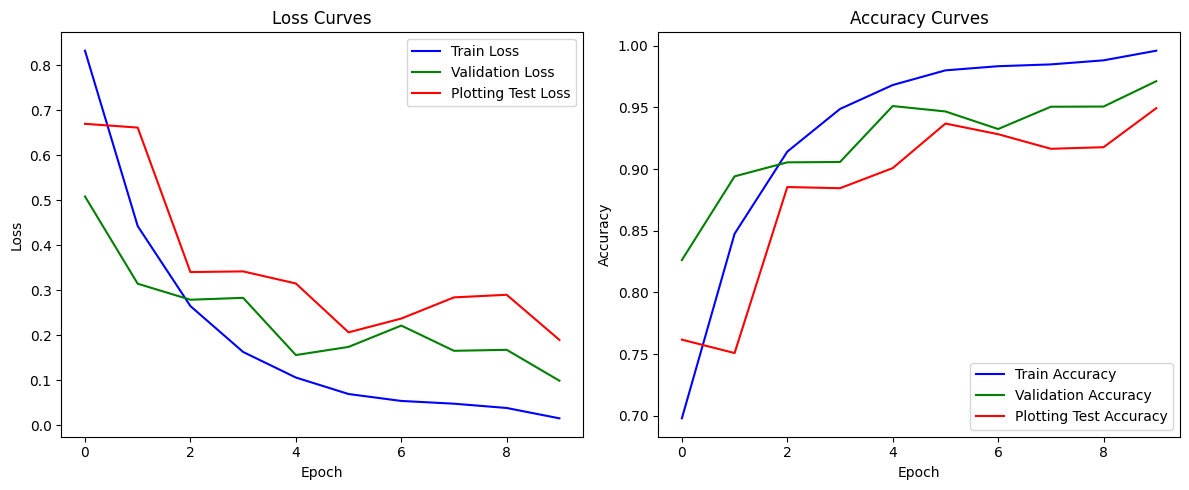

In [ ]:
# Plot training curves
plt.figure(figsize=(12, 5))

# Loss curves
plt.subplot(1, 2, 1)
plt.plot(history['train_loss'], 'b-', label='Train Loss')
plt.plot(history['val_loss'], 'g-', label='Validation Loss')
plt.plot(history['plotting_test_loss'], 'r-', label='Plotting Test Loss')
plt.title('Loss Curves')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# Accuracy curves
plt.subplot(1, 2, 2)
plt.plot([acc.item() for acc in history['train_acc']], 'b-', label='Train Accuracy')
plt.plot([acc.item() for acc in history['val_acc']], 'g-', label='Validation Accuracy')
plt.plot([acc.item() for acc in history['plotting_test_acc']], 'r-', label='Plotting Test Accuracy')
plt.title('Accuracy Curves')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

**Evaluation function**

In [ ]:
# Evaluation function for final metrics
def evaluate_model(model, dataloader):
    model.eval()
    all_preds = []
    all_labels = []
    all_probs = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs.logits, 1)
            probs = torch.nn.functional.softmax(outputs.logits, dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    return all_labels, all_preds, all_probs

# Evaluate on REAL test set and measure inference time
start_time = time.time()
test_labels, test_preds, test_probs = evaluate_model(model, test_loader)
inference_time = time.time() - start_time
print(f"Inference time for REAL test set: {inference_time:.2f} seconds")

Inference time for REAL test set: 62.16 seconds


**Metrics**

In [ ]:
# Calculate metrics on REAL test set
accuracy = accuracy_score(test_labels, test_preds)
precision = precision_score(test_labels, test_preds, average='weighted')
recall = recall_score(test_labels, test_preds, average='weighted')
f1 = f1_score(test_labels, test_preds, average='weighted')

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

# Classification report
print("\nClassification Report:")
print(classification_report(test_labels, test_preds, target_names=classes))

Accuracy: 0.9634
Precision: 0.9634
Recall: 0.9634
F1 Score: 0.9634

Classification Report:
               precision    recall  f1-score   support

Impressionism       0.98      0.98      0.98      2074
      Baroque       0.98      0.98      0.98      2102
      Realism       0.96      0.96      0.96      2093
  Romanticism       0.94      0.94      0.94      2070
Expressionism       0.96      0.95      0.96      2085

     accuracy                           0.96     10424
    macro avg       0.96      0.96      0.96     10424
 weighted avg       0.96      0.96      0.96     10424



**Confusion matrix**

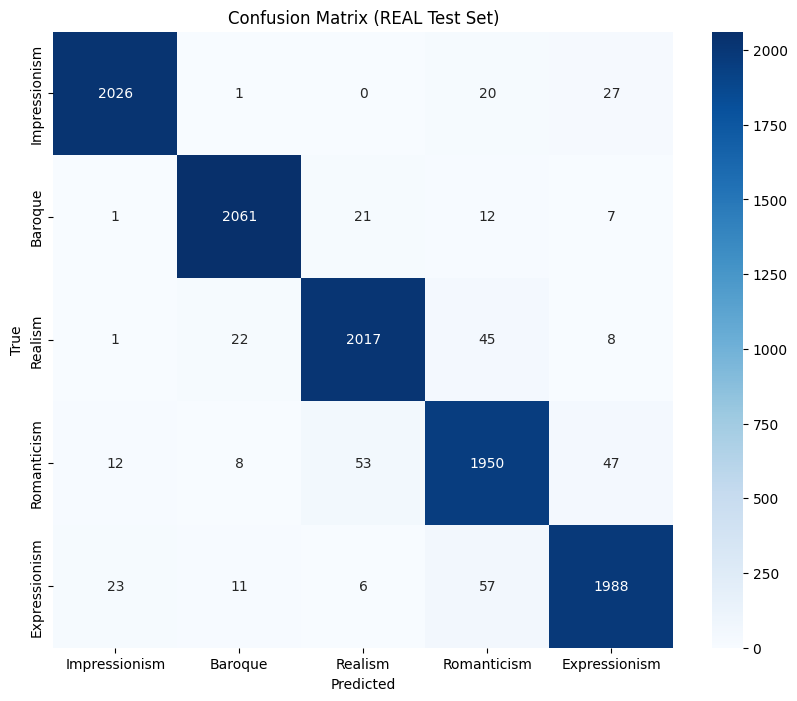

In [ ]:
# Confusion matrix
cm = confusion_matrix(test_labels, test_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=classes, yticklabels=classes)
plt.title('Confusion Matrix (REAL Test Set)')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

**ROC Curve**

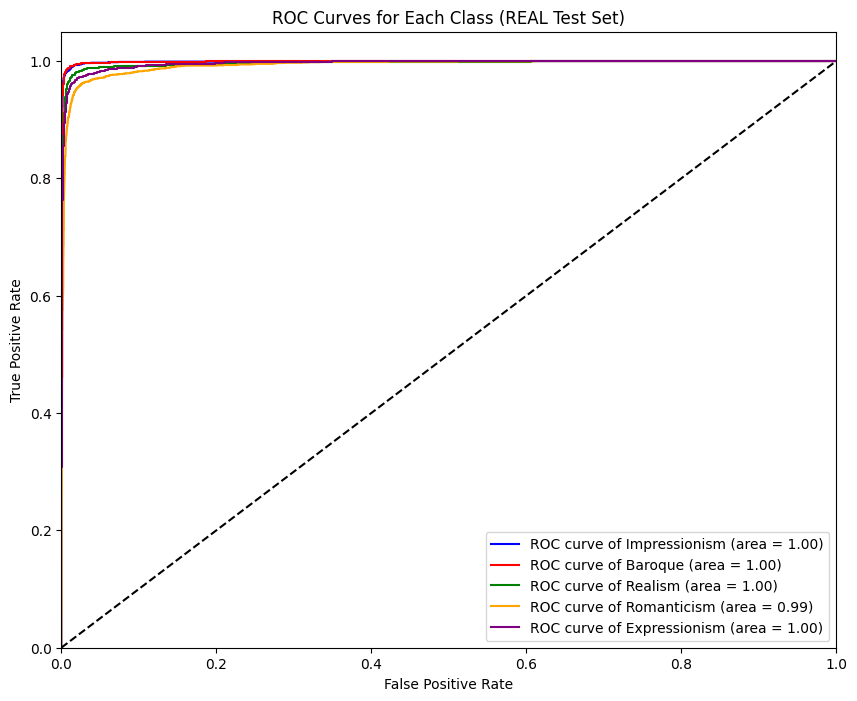

In [ ]:
# ROC Curve (One-vs-Rest)
test_labels_bin = label_binarize(test_labels, classes=range(num_classes))
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(test_labels_bin[:, i], np.array(test_probs)[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot all ROC curves
plt.figure(figsize=(10, 8))
colors = ['blue', 'red', 'green', 'orange', 'purple']
for i, color in zip(range(num_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color,
             label=f'ROC curve of {classes[i]} (area = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves for Each Class (REAL Test Set)')
plt.legend(loc="lower right")
plt.show()

**Save Results**

In [ ]:
# Save the model to Google Drive
model_save_path = '/content/drive/MyDrive/vit_art_classification.pth'
torch.save(model.state_dict(), model_save_path)

# Save performance metrics
metrics = {
    'accuracy': accuracy,
    'precision': precision,
    'recall': recall,
    'f1_score': f1,
    'training_time': training_time,
    'inference_time': inference_time,
    'roc_auc': roc_auc,
    'loss_history': {
        'train': history['train_loss'],
        'val': history['val_loss'],
        'plotting_test': history['plotting_test_loss']
    },
    'acc_history': {
        'train': [acc.item() for acc in history['train_acc']],
        'val': [acc.item() for acc in history['val_acc']],
        'plotting_test': [acc.item() for acc in history['plotting_test_acc']]
    }
}

metrics_save_path = '/content/drive/MyDrive/vit_metrics.json'
import json
with open(metrics_save_path, 'w') as f:
    json.dump(metrics, f, indent=4)

print("Model and metrics saved to Google Drive")

Model and metrics saved to Google Drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import json
metrics_save_path = '/content/drive/MyDrive/vit_metrics.json'

if os.path.exists(metrics_save_path):
    print("File exists! Reading metrics...")
    with open(metrics_save_path, 'r') as f:
        loaded_metrics = json.load(f)
    print(json.dumps(loaded_metrics, indent=4))
else:
    print("File not found! Check if the path is correct or if the file was saved properly.")

File exists! Reading metrics...
{
    "accuracy": 0.9633537989255564,
    "precision": 0.9634048997250391,
    "recall": 0.9633537989255564,
    "f1_score": 0.9633749605324975,
    "training_time": 5321.362895727158,
    "inference_time": 62.15536093711853,
    "roc_auc": {
        "0": 0.9989016277955179,
        "1": 0.9991446788183785,
        "2": 0.9962885355630107,
        "3": 0.9926534946954741,
        "4": 0.9958586434605762
    },
    "loss_history": {
        "train": [
            0.8323584102845953,
            0.4423681850857893,
            0.2645405858327975,
            0.1625667041651125,
            0.10575196909232502,
            0.06906531528470303,
            0.05367812177887255,
            0.04754764731060262,
            0.03802077575150602,
            0.014994132905366395
        ],
        "val": [
            0.5082457138494155,
            0.31429010112241146,
            0.278678245413323,
            0.28290553015794195,
            0.1556963157164187